In [4]:
import pandas as pd
#load dataset
df=pd.read_csv("car_data.csv");
#dataset first look
print("Car's dataset")
print(df)
#dataset info
print("Data set info")
print(df.info())

#description
print("summary analysis")
print(df.describe())

Car's dataset
          Make       Model  Year                Engine Fuel Type  Engine HP  \
0          BMW  1 Series M  2011     premium unleaded (required)      335.0   
1          BMW    1 Series  2011     premium unleaded (required)      300.0   
2          BMW    1 Series  2011     premium unleaded (required)      300.0   
3          BMW    1 Series  2011     premium unleaded (required)      230.0   
4          BMW    1 Series  2011     premium unleaded (required)      230.0   
...        ...         ...   ...                             ...        ...   
11909    Acura         ZDX  2012     premium unleaded (required)      300.0   
11910    Acura         ZDX  2012     premium unleaded (required)      300.0   
11911    Acura         ZDX  2012     premium unleaded (required)      300.0   
11912    Acura         ZDX  2013  premium unleaded (recommended)      300.0   
11913  Lincoln      Zephyr  2006                regular unleaded      221.0   

       Engine Cylinders Transmission 

In [5]:

# Check shape
print(df.shape)

# Check null values
print(df.isnull().sum())

# Drop duplicates
df = df.drop_duplicates()

# Fill missing values
df['Engine HP'] = df['Engine HP'].fillna(df['Engine HP'].mean())
df['Engine Cylinders'] = df['Engine Cylinders'].fillna(df['Engine Cylinders'].median())
df['Number of Doors'] = df['Number of Doors'].fillna(df['Number of Doors'].mode()[0])

(11914, 16)
Make                    0
Model                   0
Year                    0
Engine Fuel Type        3
Engine HP              69
Engine Cylinders       30
Transmission Type       0
Driven_Wheels           0
Number of Doors         6
Market Category      3742
Vehicle Size            0
Vehicle Style           0
highway MPG             0
city mpg                0
Popularity              0
MSRP                    0
dtype: int64


In [6]:
print(df.describe())

               Year     Engine HP  Engine Cylinders  Number of Doors  \
count  11199.000000  11199.000000      11199.000000     11199.000000   
mean    2010.714528    253.388859          5.666845         3.454416   
std        7.228211    109.811049          1.794696         0.872804   
min     1990.000000     55.000000          0.000000         2.000000   
25%     2007.000000    172.000000          4.000000         2.000000   
50%     2015.000000    240.000000          6.000000         4.000000   
75%     2016.000000    303.000000          6.000000         4.000000   
max     2017.000000   1001.000000         16.000000         4.000000   

        highway MPG      city mpg    Popularity          MSRP  
count  11199.000000  11199.000000  11199.000000  1.119900e+04  
mean      26.610590     19.731851   1558.483347  4.192593e+04  
std        8.977641      9.177555   1445.668872  6.153505e+04  
min       12.000000      7.000000      2.000000  2.000000e+03  
25%       22.000000     16.0000

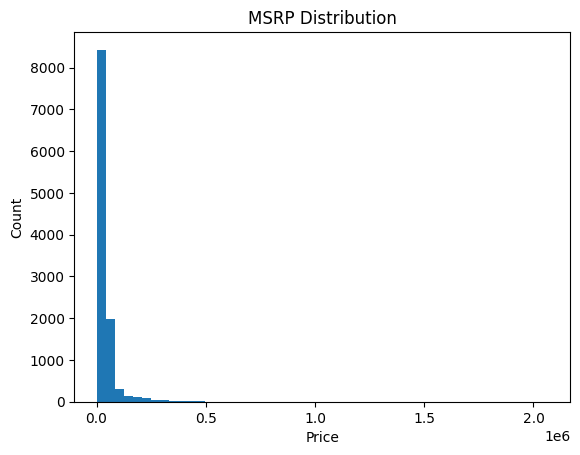

In [7]:
import matplotlib.pyplot as plt

# MSRP distribution
plt.hist(df['MSRP'], bins=50)
plt.title("MSRP Distribution")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

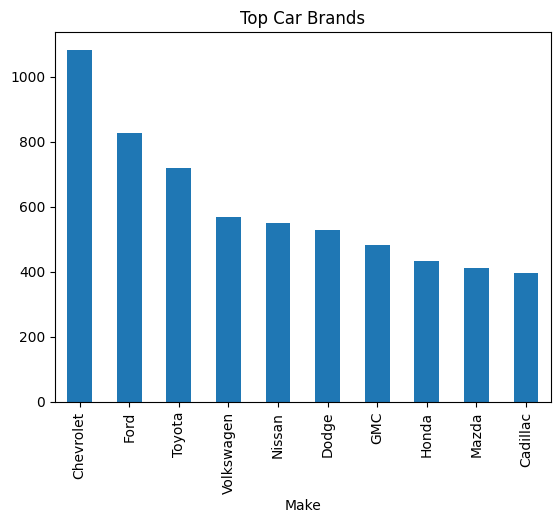

In [8]:
top_brands = df['Make'].value_counts().head(10)
top_brands.plot(kind='bar')
plt.title("Top Car Brands")
plt.show()

In [9]:
corr = df[['MSRP','Engine HP','highway MPG','city mpg']].corr()
print(corr)

                 MSRP  Engine HP  highway MPG  city mpg
MSRP         1.000000   0.658817    -0.166631 -0.162343
Engine HP    0.658817   1.000000    -0.358847 -0.349990
highway MPG -0.166631  -0.358847     1.000000  0.886299
city mpg    -0.162343  -0.349990     0.886299  1.000000


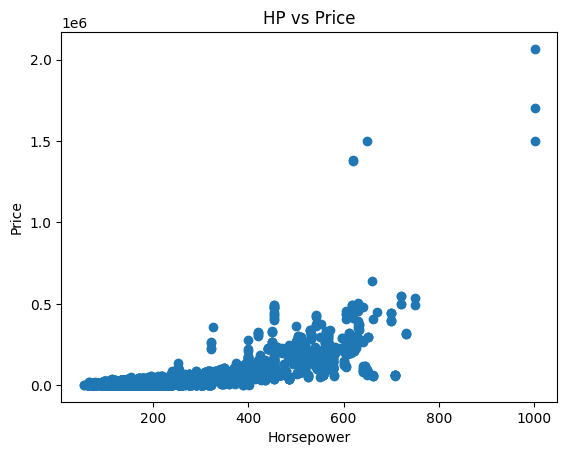

In [10]:
plt.scatter(df['Engine HP'], df['MSRP'])
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.title("HP vs Price")
plt.show()

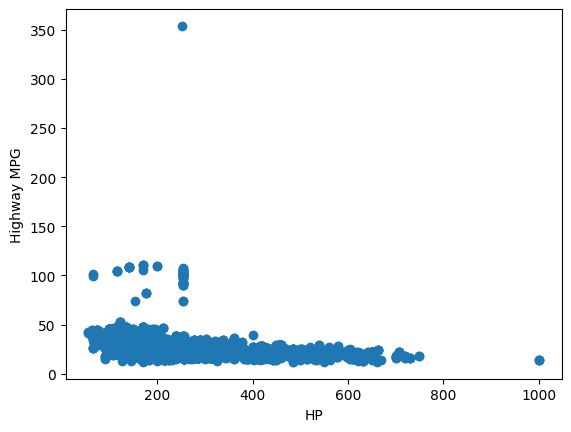

In [11]:
plt.scatter(df['Engine HP'], df['highway MPG'])
plt.xlabel("HP")
plt.ylabel("Highway MPG")
plt.show()

In [12]:
df.groupby('Make')['MSRP'].mean().sort_values(ascending=False).head(10)

Make
Bugatti         1.757224e+06
Maybach         5.462219e+05
Rolls-Royce     3.511306e+05
Lamborghini     3.315673e+05
Bentley         2.471693e+05
McLaren         2.398050e+05
Ferrari         2.382188e+05
Spyker          2.149900e+05
Aston Martin    1.981235e+05
Maserati        1.136845e+05
Name: MSRP, dtype: float64